In [9]:
import tensorflow as tf
import numpy as np
import pandas as pd
from pylab import rcParams
import matplotlib.pyplot as plt
import warnings
from mlxtend.plotting import plot_decision_regions
from matplotlib.colors import ListedColormap
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles
import seaborn as sns

In [10]:
X, y = make_circles(n_samples=100, noise=0.1, random_state=1)

<Axes: >

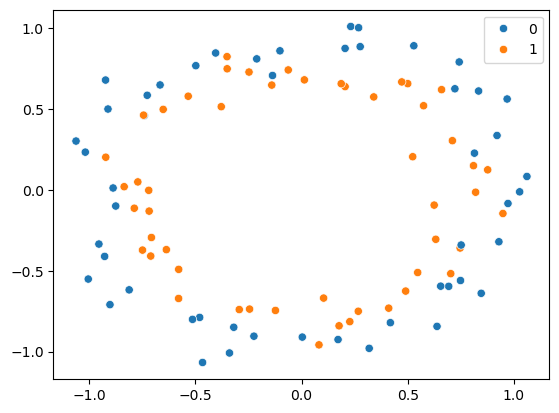

In [11]:
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=2)

In [13]:
model = Sequential()

model.add(Dense(256, input_dim=2, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

/home/ipartzix/miniconda3/envs/MLE/lib/python3.10/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [14]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [15]:
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=3500, verbose=0)

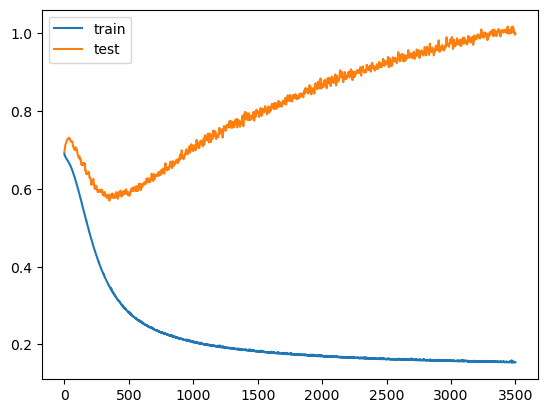

In [16]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

In [20]:
import numpy as np

print("y_train unique values:", np.unique(y_train))
print("y_train dtype:", y_train.dtype)
print("Model predictions unique values:", np.unique(model.predict(X_train)))

y_train unique values: [0 1]
y_train dtype: int64
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
Model predictions unique values: [5.52136862e-06 2.06064524e-05 2.17900633e-05 2.78985008e-05
 3.47242203e-05 7.43274941e-05 3.10651318e-04 3.11848358e-04
 3.39510472e-04 3.41540755e-04 1.84879557e-03 1.87629368e-03
 2.01280718e-03 2.60671671e-03 3.26053007e-03 3.40372953e-03
 3.66035406e-03 5.02267806e-03 6.73223147e-03 9.47307888e-03
 9.96200647e-03 1.14558544e-02 2.64352672e-02 2.64827181e-02
 2.80853454e-02 3.63759510e-02 4.79734465e-02 1.06305510e-01
 1.12087153e-01 1.19940005e-01 1.68003127e-01 1.69019461e-01
 1.69915020e-01 1.86721191e-01 2.22028062e-01 3.86928111e-01
 4.33507502e-01 4.86699730e-01 5.22746146e-01 5.68356693e-01
 6.12471759e-01 6.87408328e-01 7.35069931e-01 7.54279912e-01
 7.91175663e-01 7.95830846e-01 8.14092278e-01 8.37638021e-01
 8.69514644e-01 8.81728172e-01 9.25290763e-01 9.33088303e-01
 9.36916709e-01 9.50397611e-01 9.54071283e-01 9.62831676e-01
 9.67553973e-01 9.8568713

In [23]:
import numpy as np

# Check what the model actually predicts
sample_preds = model.predict(X_train[:5])
print("Model predictions sample:", sample_preds)
print("Model predictions dtype:", sample_preds.dtype)

# Check your training labels
print("Unique y_train values:", np.unique(y_train))
print("y_train dtype:", y_train.dtype)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
Model predictions sample: [[0.00996201]
 [0.48669973]
 [0.00187629]
 [0.79583085]
 [0.68740827]]
Model predictions dtype: float32
Unique y_train values: [0 1]
y_train dtype: int64


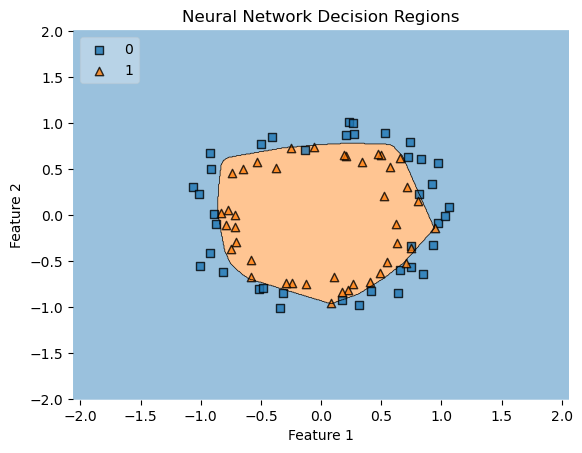

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from mlxtend.plotting import plot_decision_regions


class ProbabilityClassifierWrapper:
    def __init__(self, model, threshold=0.5):
        self.model = model
        self.threshold = threshold

    def predict(self, X):
        # Get probabilities and convert to binary class labels (0 or 1)
        preds = self.model.predict(X, verbose=0)
        return (preds >= self.threshold).astype(int).ravel()


# Wrap your model
wrapped_model = ProbabilityClassifierWrapper(model)

# Ensure data is a numpy array
X_train_np = X_train.to_numpy() if hasattr(X_train, "to_numpy") else X_train

# Plot decision regions successfully
plot_decision_regions(X_train_np, y_train.ravel(), clf=wrapped_model, legend=2)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Neural Network Decision Regions")
plt.show()

# Early Stopping

In [25]:
model = Sequential()

model.add(Dense(256, input_dim=2, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [26]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [27]:
callback = EarlyStopping(
    monitor="val_loss",
    min_delta=0.00001,
    patience=20,
    verbose=1,
    mode="auto",
    baseline=None,
    restore_best_weights=False
)

In [28]:
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=3500, callbacks=callback)

Epoch 1/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 315ms/step - accuracy: 0.4750 - loss: 0.6999 - val_accuracy: 0.6000 - val_loss: 0.6798
Epoch 2/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.4875 - loss: 0.6964 - val_accuracy: 0.5500 - val_loss: 0.6841
Epoch 3/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.4875 - loss: 0.6933 - val_accuracy: 0.5500 - val_loss: 0.6864
Epoch 4/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.4875 - loss: 0.6922 - val_accuracy: 0.4500 - val_loss: 0.6887
Epoch 5/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.5375 - loss: 0.6903 - val_accuracy: 0.5500 - val_loss: 0.6905
Epoch 6/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.5125 - loss: 0.6891 - val_accuracy: 0.6000 - val_loss: 0.6923
Epoch 7/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.5250 - loss: 0.6875 - val_accuracy: 0.6000 - val_loss: 0.6943
Epoch 8/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.6000 - loss: 0.6865 - val_accuracy: 0.5500 - 

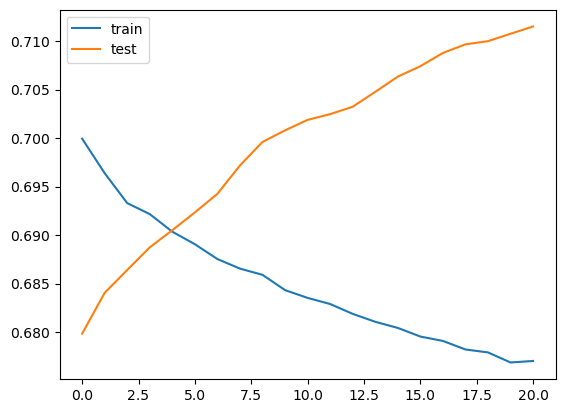

In [29]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

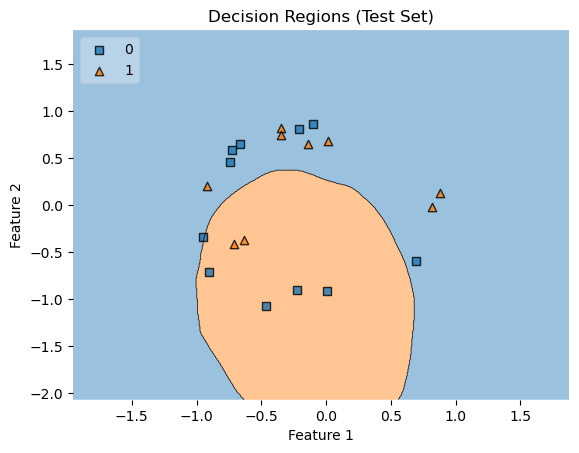

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from mlxtend.plotting import plot_decision_regions


class ProbabilityClassifierWrapper:
    def __init__(self, model, threshold=0.5):
        self.model = model
        self.threshold = threshold

    def predict(self, X):
        # 1. Get raw predictions
        preds = self.model.predict(X, verbose=0)

        # 2. Threshold probabilities and explicitly cast to standard int array
        return (preds >= self.threshold).astype(int).reshape(-1)


# Re-wrap your model with the strict typecasting
wrapped_model = ProbabilityClassifierWrapper(model)

# Ensure features are a NumPy array
X_test_np = X_test.to_numpy() if hasattr(X_test, "to_numpy") else X_test

# Plot decision regions successfully
plot_decision_regions(X_test_np, y_test.ravel(), clf=wrapped_model, legend=2)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Decision Regions (Test Set)")
plt.show()

- Early stopping is a regularization technique used in machine learning to prevent overfitting by terminating training as soon as the model's performance on a validation dataset begins to decline.